# Premier League Match Analysis and Prediction

Analysing four Premier League seasons (2021/22 to 2024/25) with SQL, then predicting match results with a Poisson model and comparing those predictions against Bet365's odds.

## Step 0: Setup check

This cell imports every library the project needs and prints its version. If it runs without an error, the environment is ready.

In [1]:
import sys                # Tells us which Python is running this notebook
import sqlite3            # SQL database, built into Python (no install needed)

import pandas as pd       # Tables of data (loading, cleaning, grouping)
import numpy as np        # Fast maths on arrays of numbers
import scipy              # Scientific maths (we'll use its Poisson distribution)
import matplotlib         # Charts

# This path should point inside the project's venv folder.
# If it does, the notebook is using the right environment.
print("Python running from:", sys.executable)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scipy:", scipy.__version__)
print("matplotlib:", matplotlib.__version__)
print("sqlite:", sqlite3.sqlite_version)

Python running from: D:\Desktop\premier-league-match-predictor\venv\Scripts\python.exe
pandas: 3.1.1
numpy: 2.5.4
scipy: 1.18.1
matplotlib: 3.11.2
sqlite: 3.50.4


## Step 1: Load the data

Each season is a separate CSV file on football-data.co.uk. This cell downloads all four, labels every row with its season, and stacks them into one table. A Premier League season has 20 teams playing 380 matches, so we expect 380 rows per season and 1,520 in total.

In [2]:
# Each season's URL uses a short code: "2122" means 2021/22.
# This dictionary pairs each code with the label we want to use for that season.
seasons = {
    "2122": "2021/22",
    "2223": "2022/23",
    "2324": "2023/24",
    "2425": "2024/25",
}

season_tables = []  # An empty list to hold one table per season

for code, label in seasons.items():
    url = f"https://www.football-data.co.uk/mmz4281/{code}/E0.csv"  # E0 = England's top division
    season_df = pd.read_csv(url).copy()  # Download the CSV into a table (.copy() tidies its memory layout)
    season_df["Season"] = label          # Add a column recording which season each row is from
    season_tables.append(season_df)      # Keep it until all four are loaded

# Stack the four tables on top of each other. ignore_index=True renumbers the rows
# 0, 1, 2... so that row numbers don't restart at 0 for each season.
raw_matches = pd.concat(season_tables, ignore_index=True)

# Check 1: the overall size, as (rows, columns)
print("Rows and columns:", raw_matches.shape)

# Check 2: each season should have exactly 380 matches
print("\nMatches per season:")
print(raw_matches["Season"].value_counts().sort_index())

# Check 3: look at the first few rows, using only the columns we plan to keep
columns_to_show = ["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "B365H", "B365D", "B365A"]
raw_matches[columns_to_show].head()

Rows and columns: (1520, 133)

Matches per season:
Season
2021/22    380
2022/23    380
2023/24    380
2024/25    380
Name: count, dtype: int64


,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,B365H,B365D,B365A
0,2021/22,13/08/2021,Brentford,Arsenal,2,0,H,4.00,3.40,1.95
1,2021/22,14/08/2021,Man United,Leeds,5,1,H,1.53,4.50,5.75
2,2021/22,14/08/2021,Burnley,Brighton,1,2,A,3.10,3.10,2.45
3,2021/22,14/08/2021,Chelsea,Crystal Palace,3,0,H,1.25,5.75,13.00
4,2021/22,14/08/2021,Everton,Southampton,3,1,H,1.90,3.50,4.00


## Step 2: Clean the data

The raw table has 133 columns, but this project only needs 10. The first cell keeps those columns, then checks for missing values and looks at each column's data type.

In [3]:
# The 10 columns the project needs
columns_to_keep = ["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "B365H", "B365D", "B365A"]

# .copy() makes an independent table, so changes here can't affect raw_matches
matches = raw_matches[columns_to_keep].copy()

# isna() marks each empty cell as True, and sum() counts them for each column
print("Missing values in each column:")
print(matches.isna().sum())

# dtypes shows how pandas is storing each column
print("\nData types before cleaning:")
print(matches.dtypes)

Missing values in each column:
Season      0
Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
B365H       0
B365D       0
B365A       0
dtype: int64

Data types before cleaning:
Season          str
Date            str
HomeTeam        str
AwayTeam        str
FTHG          int64
FTAG          int64
FTR             str
B365H       float64
B365D       float64
B365A       float64
dtype: object


In [4]:
# Date is stored as text, so convert it to a real date.
# The format is day/month/year. Stating it means 05/08/2022 is read as 5 August, not May 8.
matches["Date"] = pd.to_datetime(matches["Date"], format="%d/%m/%Y")

# Put the matches in time order. reset_index(drop=True) renumbers the rows afterwards.
matches = matches.sort_values("Date").reset_index(drop=True)

print("Data type of Date now:", matches["Date"].dtype)
print("\nFirst and last match date in each season:")
print(matches.groupby("Season")["Date"].agg(["min", "max"]))

Data type of Date now: datetime64[us]

First and last match date in each season:
               min        max
Season                       
2021/22 2021-08-13 2022-05-22
2022/23 2022-08-05 2023-05-28
2023/24 2023-08-11 2024-05-19
2024/25 2024-08-16 2025-05-25


In [5]:
# Sanity checks: no missing values doesn't guarantee that the values make sense.

# Check 1: each home/away pairing should happen only once per season
duplicates = matches.duplicated(subset=["Season", "HomeTeam", "AwayTeam"]).sum()
print("Duplicate fixtures:", duplicates)

# Check 2: work out the result from the score and compare it with the FTR column
calculated_result = np.where(matches["FTHG"] > matches["FTAG"], "H",
                    np.where(matches["FTHG"] < matches["FTAG"], "A", "D"))
print("Results that don't match the score:", (calculated_result != matches["FTR"]).sum())

# Check 3: goals can't be negative, and decimal odds must be above 1
print("Lowest goal count:", matches[["FTHG", "FTAG"]].min().min())
print("Lowest odds:", matches[["B365H", "B365D", "B365A"]].min().min())

# Check 4: every season should have 20 teams
print("\nTeams per season:")
print(matches.groupby("Season")["HomeTeam"].nunique())

# Check 5: read the team names, looking for the same club spelled two ways
all_teams = sorted(set(matches["HomeTeam"]) | set(matches["AwayTeam"]))
print("\nAll", len(all_teams), "teams:")
print(all_teams)

print("\nFinal shape:", matches.shape)

Duplicate fixtures: 0
Results that don't match the score: 0
Lowest goal count: 0
Lowest odds: 1.06

Teams per season:
Season
2021/22    20
2022/23    20
2023/24    20
2024/25    20
Name: HomeTeam, dtype: int64

All 26 teams:
['Arsenal', 'Aston Villa', 'Bournemouth', 'Brentford', 'Brighton', 'Burnley', 'Chelsea', 'Crystal Palace', 'Everton', 'Fulham', 'Ipswich', 'Leeds', 'Leicester', 'Liverpool', 'Luton', 'Man City', 'Man United', 'Newcastle', 'Norwich', "Nott'm Forest", 'Sheffield United', 'Southampton', 'Tottenham', 'Watford', 'West Ham', 'Wolves']

Final shape: (1520, 10)


### Cleaning decisions

| Decision | Reason |
|---|---|
| Kept 10 of the 133 columns | The project only uses the match details, the score, the result and Bet365's odds. |
| Used Bet365 as the only bookmaker | One bookmaker keeps the comparison simple, and its odds are complete for all 1,520 matches. |
| Removed no rows | There are no missing values or duplicate fixtures, so there is nothing to remove. Each season keeps all 380 matches. |
| Converted `Date` from text to a real date | Dates stored as text can't be reliably sorted or compared. The format is stated explicitly so that day and month can't be swapped. |
| Sorted the matches by date | The model must only learn from the past, so the data should be in time order. |
| Left the other data types unchanged | Goals are already whole numbers, odds are already decimals, and team names, results and seasons are already text. |
| Left team names unchanged | There are 26 different clubs across the four seasons, and each club has one spelling. |
| Kept high-scoring matches and long odds | The highest values (9 goals, odds of 29.0) are unusual but realistic. Removing them would hide real results from the model. |

## Step 3: SQL analysis

This step loads the cleaned table into a SQLite database and answers four questions with SQL. The queries are stored in [sql/analysis.sql](sql/analysis.sql), with comments explaining each one. Each cell below prints a query from that file, with its result directly underneath.

In [6]:
from model import load_queries

# ":memory:" creates the database in the computer's memory rather than in a file.
# It's rebuilt from the cleaned data each time the notebook runs.
conn = sqlite3.connect(":memory:")

# Copy the pandas table into a SQL table called "matches".
# index=False leaves out pandas' row numbers, which we don't need.
matches.to_sql("matches", conn, index=False, if_exists="replace")

# Load the queries from the SQL file, as a dictionary of {name: query}
queries = load_queries("sql/analysis.sql")
print("Queries loaded:", list(queries))

# Check that every row arrived. read_sql_query runs SQL and returns the result as a table.
pd.read_sql_query("SELECT COUNT(*) AS total_matches FROM matches", conn)

Queries loaded: ['result_percentages', 'goals_per_season', 'top_scoring_teams', 'best_defensive_teams', 'favourite_win_rate']


,total_matches
0,1520


In [7]:
# Question 1: What percentage of matches are home wins, draws and away wins?
print(queries["result_percentages"])
pd.read_sql_query(queries["result_percentages"], conn)

-- Question 1: What percentage of matches are home wins, draws and away wins?
-- GROUP BY makes one row per result. The inner SELECT gets the total number of matches.
-- 100.0 (not 100) forces decimal division, because whole-number division would drop the decimals.
SELECT
    CASE FTR
        WHEN 'H' THEN 'Home win'
        WHEN 'D' THEN 'Draw'
        WHEN 'A' THEN 'Away win'
    END AS result,
    COUNT(*) AS matches,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM matches), 1) AS percentage
FROM matches
GROUP BY FTR
ORDER BY matches DESC;


,result,matches,percentage
0,Home win,677,44.5
1,Away win,493,32.4
2,Draw,350,23.0


In [8]:
# Question 2: How many goals per match were scored in each season?
print(queries["goals_per_season"])
pd.read_sql_query(queries["goals_per_season"], conn)

-- Question 2: How many goals per match were scored in each season?
-- Total goals in a match = home goals + away goals. AVG then averages that across each season.
SELECT
    Season,
    COUNT(*) AS matches,
    SUM(FTHG + FTAG) AS total_goals,
    ROUND(AVG(FTHG + FTAG), 2) AS goals_per_match
FROM matches
GROUP BY Season
ORDER BY Season;


,Season,matches,total_goals,goals_per_match
0,2021/22,380,1071,2.82
1,2022/23,380,1084,2.85
2,2023/24,380,1246,3.28
3,2024/25,380,1115,2.93


In [9]:
# Question 3a: Which teams scored the most goals per match?
print(queries["top_scoring_teams"])
pd.read_sql_query(queries["top_scoring_teams"], conn)

-- Question 3a: Which teams scored the most goals per match?
-- Each match row holds two teams, so the WITH block (a CTE) first builds a temporary table
-- with one row per team per match. UNION ALL stacks the home view and the away view.
-- Teams are ranked per match because not every team played all four seasons, which makes totals unfair.
WITH team_matches AS (
    SELECT HomeTeam AS team, FTHG AS scored FROM matches
    UNION ALL
    SELECT AwayTeam AS team, FTAG AS scored FROM matches
)
SELECT
    team,
    COUNT(*) AS matches,
    SUM(scored) AS goals_scored,
    ROUND(1.0 * SUM(scored) / COUNT(*), 2) AS scored_per_match
FROM team_matches
GROUP BY team
ORDER BY 1.0 * SUM(scored) / COUNT(*) DESC
LIMIT 5;


,team,matches,goals_scored,scored_per_match
0,Man City,152,361,2.38
1,Liverpool,152,341,2.24
2,Arsenal,152,309,2.03
3,Tottenham,152,277,1.82
4,Newcastle,152,265,1.74


In [10]:
# Question 3b: Which teams conceded the fewest goals per match?
print(queries["best_defensive_teams"])
pd.read_sql_query(queries["best_defensive_teams"], conn)

-- Question 3b: Which teams conceded the fewest goals per match?
-- Same idea as 3a, but a home team concedes the away goals and an away team concedes the home goals.
-- ASC puts the lowest values first, because fewer goals conceded is better.
WITH team_matches AS (
    SELECT HomeTeam AS team, FTAG AS conceded FROM matches
    UNION ALL
    SELECT AwayTeam AS team, FTHG AS conceded FROM matches
)
SELECT
    team,
    COUNT(*) AS matches,
    SUM(conceded) AS goals_conceded,
    ROUND(1.0 * SUM(conceded) / COUNT(*), 2) AS conceded_per_match
FROM team_matches
GROUP BY team
ORDER BY 1.0 * SUM(conceded) / COUNT(*) ASC
LIMIT 5;


,team,matches,goals_conceded,conceded_per_match
0,Man City,152,137,0.90
1,Arsenal,152,154,1.01
2,Liverpool,152,155,1.02
3,Chelsea,152,186,1.22
4,Crystal Palace,152,204,1.34


In [11]:
# Question 4: How often did the bookmaker's favourite actually win?
print(queries["favourite_win_rate"])
pd.read_sql_query(queries["favourite_win_rate"], conn)

-- Question 4: How often did the bookmaker's favourite actually win?
-- The favourite is the outcome with the lowest odds, because low odds mean the bookmaker thinks it's most likely.
-- If two outcomes share the lowest odds, there is no single favourite, so the match is excluded and counted separately.
-- In SQLite, (favourite = FTR) gives 1 when true and 0 when false, so SUM counts the correct picks.
WITH favourites AS (
    SELECT
        FTR,
        CASE
            WHEN B365H < B365D AND B365H < B365A THEN 'H'
            WHEN B365A < B365H AND B365A < B365D THEN 'A'
            WHEN B365D < B365H AND B365D < B365A THEN 'D'
            ELSE 'None'
        END AS favourite
    FROM matches
)
SELECT
    CASE favourite
        WHEN 'H' THEN 'Home favourite'
        WHEN 'A' THEN 'Away favourite'
        WHEN 'D' THEN 'Draw favourite'
    END AS category,
    COUNT(*) AS matches,
    SUM(favourite = FTR) AS favourite_won,
    ROUND(100.0 * SUM(favourite = FTR) / COUNT(*), 1) AS win_p

,category,matches,favourite_won,win_percentage
0,Away favourite,561,308.0,54.9
1,Home favourite,941,550.0,58.4
2,All clear favourites,1502,858.0,57.1
3,No clear favourite (excluded),18,NaN,NaN


### What the SQL shows

- **Results:** home teams won 44.5% of matches, away teams 32.4%, and 23.0% were draws. Home teams won noticeably more often than away teams.
- **Goals:** 2023/24 stands out at 3.28 goals per match. The other three seasons were between 2.82 and 2.93.
- **Teams:** Man City ranked first for both attack (2.38 scored per match) and defence (0.90 conceded per match). Liverpool and Arsenal were also in the top three for both.
- **Favourites:** the bookmaker's favourite won 57.1% of the 1,502 matches that had a clear favourite. That beats always picking the home team (44.5%), but the favourite still failed to win more than 4 times in 10. A draw was never the outright favourite.

## Step 4: Exploratory analysis

Four charts look for the patterns a prediction model should capture: home advantage, how goals are distributed, how teams differ, and how reliable the bookmaker's favourite is. The first cell sets one shared style so that all the charts match.

In [12]:
import matplotlib.pyplot as plt

# Colours used across the charts (tested to stay distinct for colourblind readers)
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#1baf7a"
BACKGROUND = "#fcfcfb"
TEXT = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

# rcParams holds matplotlib's default settings. Changing them here styles every chart below.
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": MUTED_TEXT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.spines.top": False,      # Remove the top and right borders, which add no information
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,        # Draw gridlines behind the data
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED_TEXT,
    "ytick.color": MUTED_TEXT,
})

FTR         A     D     H
Season                   
2021/22  33.9  23.2  42.9
2022/23  28.7  22.9  48.4
2023/24  32.4  21.6  46.1
2024/25  34.7  24.5  40.8


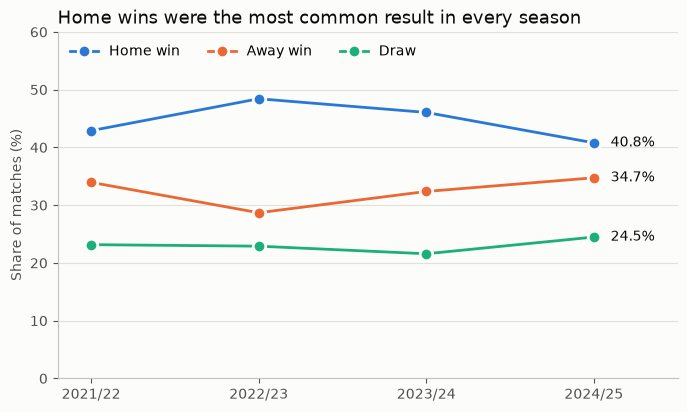

In [13]:
# Chart 1: Home advantage by season

# crosstab counts each result per season. normalize="index" turns counts into shares of each season.
result_share = pd.crosstab(matches["Season"], matches["FTR"], normalize="index") * 100
print(result_share.round(1))

fig, ax = plt.subplots()

# Draw one line per result: (column in the table, legend label, colour)
for result, label, colour in [("H", "Home win", BLUE), ("A", "Away win", ORANGE), ("D", "Draw", GREEN)]:
    values = result_share[result]
    ax.plot(values.index, values, label=label, color=colour, linewidth=2,
            marker="o", markersize=9, markeredgecolor=BACKGROUND, markeredgewidth=2)
    # Write the latest value just to the right of the final point
    ax.text(3.1, values.iloc[-1], f"{values.iloc[-1]:.1f}%", va="center", color=TEXT)

ax.set_title("Home wins were the most common result in every season")
ax.set_ylabel("Share of matches (%)")
ax.set_ylim(0, 60)            # Start at 0 so that differences aren't exaggerated
ax.set_xlim(-0.2, 3.5)        # Leave room for the labels on the right
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()

**Finding:** Home wins were the most common result in all four seasons, between 40.8% and 48.4%, so the model should treat home and away teams separately. The home win rate was lowest in 2024/25, which is the season we'll test on.

Average goals per match: 2.97
0     4.7
1    15.3
2    23.0
3    21.4
4    17.6
5    10.5
6     4.7
7     2.0
8     0.5
9     0.3
Name: proportion, dtype: float64


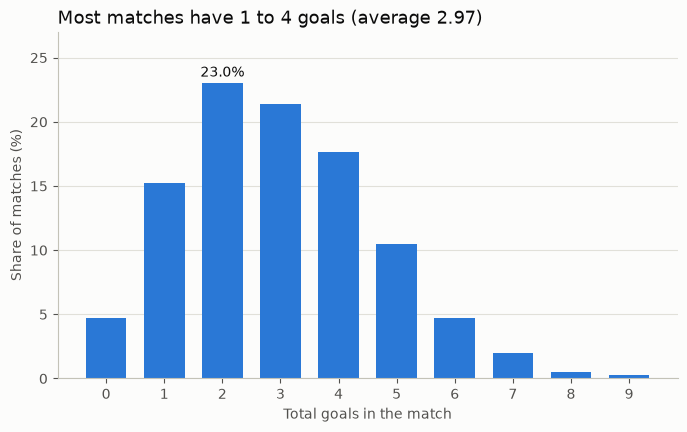

In [14]:
# Chart 2: Distribution of goals per match

total_goals = matches["FTHG"] + matches["FTAG"]

# value_counts counts how often each total occurs. normalize=True turns counts into shares.
goal_share = total_goals.value_counts(normalize=True).sort_index() * 100
print("Average goals per match:", round(total_goals.mean(), 2))
print(goal_share.round(1))

fig, ax = plt.subplots()
ax.bar(goal_share.index, goal_share.values, width=0.7, color=BLUE)

# Label only the tallest bar, because the y-axis covers the rest
most_common = goal_share.idxmax()
ax.text(most_common, goal_share.max() + 0.5, f"{goal_share.max():.1f}%", ha="center", color=TEXT)

ax.set_title(f"Most matches have 1 to 4 goals (average {total_goals.mean():.2f})")
ax.set_xlabel("Total goals in the match")
ax.set_ylabel("Share of matches (%)")
ax.set_xticks(goal_share.index)   # Show a tick for each goal total that occurred
ax.set_ylim(0, 27)                # Leave room for the label above the tallest bar
ax.grid(axis="x", visible=False)
plt.show()

**Finding:** About 77% of matches had between 1 and 4 goals, and 2 goals was the most common total (23.0%). Matches with 7 or more goals were rare, at about 3%. Goal counts bunch around a low average and tail off to the right, which is the kind of pattern a Poisson model is designed for.

                  Matches  Scored  Conceded
Team                                       
Man City              152    2.38      0.90
Liverpool             152    2.24      1.02
Arsenal               152    2.03      1.01
Tottenham             152    1.82      1.51
Newcastle             152    1.74      1.34
Chelsea               152    1.68      1.22
Aston Villa           152    1.56      1.39
Brighton              152    1.55      1.43
Brentford             152    1.50      1.47
Fulham                114    1.44      1.47
Man United            152    1.42      1.39
Luton                  38    1.37      2.24
West Ham              152    1.37      1.59
Bournemouth           114    1.31      1.61
Crystal Palace        152    1.30      1.34
Leicester             114    1.28      1.82
Nott'm Forest         114    1.27      1.59
Leeds                  76    1.18      2.07
Wolves                152    1.14      1.55
Everton               152    1.05      1.43
Burnley                76    0.9

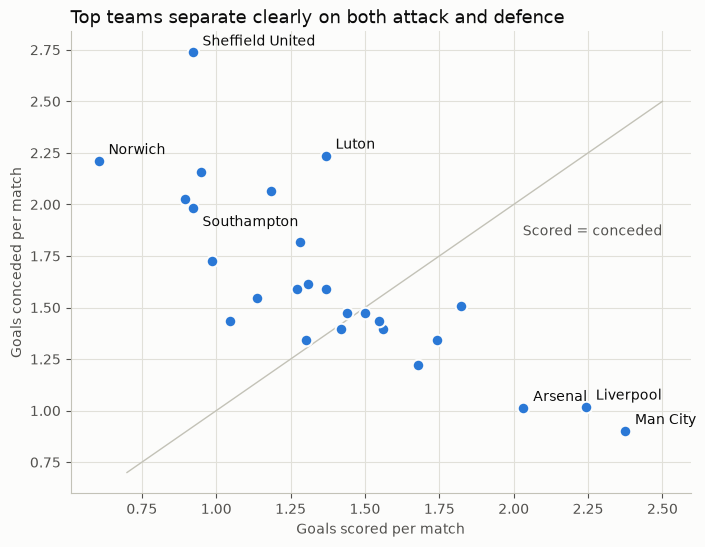

In [15]:
# Chart 3: Goals scored vs conceded by team

# Build one row per team per match, as in the SQL query, using a home view and an away view
home_view = matches[["HomeTeam", "FTHG", "FTAG"]].set_axis(["Team", "Scored", "Conceded"], axis=1)
away_view = matches[["AwayTeam", "FTAG", "FTHG"]].set_axis(["Team", "Scored", "Conceded"], axis=1)
team_view = pd.concat([home_view, away_view], ignore_index=True)

# Average per match, so that teams with fewer seasons can be compared fairly
team_stats = team_view.groupby("Team").agg(
    Matches=("Scored", "size"),
    Scored=("Scored", "mean"),
    Conceded=("Conceded", "mean"),
).sort_values("Scored", ascending=False)
print(team_stats.round(2))

fig, ax = plt.subplots(figsize=(8, 6))

# Teams on this line score as many as they concede. Teams below it score more.
ax.plot([0.7, 2.5], [0.7, 2.5], color=AXIS, linewidth=1)
ax.text(2.5, 1.85, "Scored = conceded", color=MUTED_TEXT, ha="right")

ax.scatter(team_stats["Scored"], team_stats["Conceded"], s=70, color=BLUE,
           edgecolors=BACKGROUND, linewidths=1.5, zorder=3)

# Label only the teams at the extremes, because 26 labels would be unreadable.
# Each label has its own position (in points from the dot) so that it doesn't cover a nearby dot.
labels = {
    "Man City": (7, 5),
    "Liverpool": (7, 5),
    "Arsenal": (7, 5),
    "Sheffield United": (7, 5),
    "Luton": (7, 5),
    "Norwich": (7, 5),
    "Southampton": (7, -13),
}
for team, offset in labels.items():
    ax.annotate(team, (team_stats.loc[team, "Scored"], team_stats.loc[team, "Conceded"]),
                xytext=offset, textcoords="offset points", color=TEXT)

ax.set_title("Top teams separate clearly on both attack and defence")
ax.set_xlabel("Goals scored per match")
ax.set_ylabel("Goals conceded per match")
plt.show()

**Finding:** Man City, Liverpool and Arsenal stand apart, scoring over 2 goals per match and conceding about 1. Attack and defence don't always go together: Tottenham scored 1.82 but conceded 1.51, while Crystal Palace scored 1.30 and conceded 1.34. That's why the model rates them separately. Some teams played only one season (38 matches), so their numbers are less reliable.

Matches with a clear favourite: 1502
Overall favourite win rate: 57.1
Season
2021/22    58.4
2022/23    56.4
2023/24    59.4
2024/25    54.3
dtype: float64


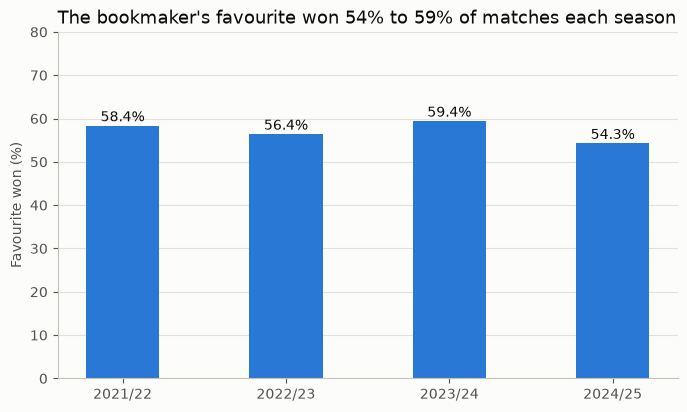

In [16]:
# Chart 4: How often the bookmaker's favourite won, by season

odds = matches[["B365H", "B365D", "B365A"]]

# A clear favourite means exactly one outcome has the lowest odds (the same rule as the SQL query)
has_clear_favourite = odds.eq(odds.min(axis=1), axis=0).sum(axis=1) == 1

# idxmin gives the column with the lowest odds, such as "B365H". The last letter is the result code.
favourite = odds.idxmin(axis=1).str[-1]

# Compare the favourite with the actual result, keeping only matches with a clear favourite
favourite_won = (favourite == matches["FTR"])[has_clear_favourite]

# The mean of True/False values is the share that are True
favourite_win_rate = favourite_won.groupby(matches["Season"]).mean() * 100
print("Matches with a clear favourite:", has_clear_favourite.sum())
print("Overall favourite win rate:", round(favourite_won.mean() * 100, 1))
print(favourite_win_rate.round(1))

fig, ax = plt.subplots()
ax.bar(favourite_win_rate.index, favourite_win_rate.values, width=0.45, color=BLUE)

# With only four bars, each one can carry its value
for season, rate in favourite_win_rate.items():
    ax.text(season, rate + 1, f"{rate:.1f}%", ha="center", color=TEXT)

ax.set_title("The bookmaker's favourite won 54% to 59% of matches each season")
ax.set_ylabel("Favourite won (%)")
ax.set_ylim(0, 80)            # Start at 0 so that differences aren't exaggerated
ax.grid(axis="x", visible=False)
plt.show()

**Finding:** The favourite won 57.1% of matches overall and stayed in a fairly narrow range, from 54.3% to 59.4%. So the favourite usually wins, but far from always. The rate was lowest in 2024/25, which suggests the test season may be a slightly harder one to predict.

## Step 5: Train/test split

The model learns from the first three seasons and is tested on 2024/25. We split by time rather than at random because a real forecast can only use the past. A random split would let the model learn from matches played after the ones it's predicting, which would make its results look better than they really are.

In [17]:
test_season = "2024/25"

# Each comparison gives True or False per row, and the table keeps only the True rows.
# .copy() makes each table independent, so later changes can't affect matches.
train = matches[matches["Season"] != test_season].copy()
test = matches[matches["Season"] == test_season].copy()

# Check 1: the two tables together should contain every match
print("Training matches:", len(train))
print("Test matches:", len(test))
print("Total:", len(train) + len(test), "out of", len(matches))

# Check 2: all training matches should be played before the first test match
print("\nTraining dates:", train["Date"].min().date(), "to", train["Date"].max().date())
print("Test dates:", test["Date"].min().date(), "to", test["Date"].max().date())
print("Training ends before testing starts:", train["Date"].max() < test["Date"].min())

# Check 3: which test season teams never appear in the training data?
train_teams = set(train["HomeTeam"]) | set(train["AwayTeam"])
test_teams = set(test["HomeTeam"]) | set(test["AwayTeam"])
new_teams = sorted(test_teams - train_teams)   # Teams in test but not in training
print("\nTest season teams with no training data:", new_teams)

# Count the test matches affected. The model can't rate these teams, so step 9 will skip them.
involves_new_team = test["HomeTeam"].isin(new_teams) | test["AwayTeam"].isin(new_teams)
print("Test matches involving those teams:", involves_new_team.sum())
print("Test matches the model can predict:", (~involves_new_team).sum())

Training matches: 1140
Test matches: 380
Total: 1520 out of 1520

Training dates: 2021-08-13 to 2024-05-19
Test dates: 2024-08-16 to 2025-05-25
Training ends before testing starts: True

Test season teams with no training data: ['Ipswich']
Test matches involving those teams: 38
Test matches the model can predict: 342


## Step 6: Team strengths

Each team gets four ratings, each comparing the team to the league average. Everything here uses only the training data.

| Rating | Calculation | How to read it |
|---|---|---|
| Home attack | Goals scored per home match ÷ league average home goals | Above 1 is better than average |
| Home defence | Goals conceded per home match ÷ league average away goals | **Below** 1 is better than average |
| Away attack | Goals scored per away match ÷ league average away goals | Above 1 is better than average |
| Away defence | Goals conceded per away match ÷ league average home goals | **Below** 1 is better than average |

A home team concedes goals to away teams, so home defence is compared with the league's average **away** goals. Away defence works the opposite way round.

In [18]:
from model import calculate_team_strengths

# Work out the ratings using the training data only. The function is in model.py.
team_strengths, avg_home_goals, avg_away_goals = calculate_team_strengths(train)
print("League average home goals per match:", round(avg_home_goals, 3))
print("League average away goals per match:", round(avg_away_goals, 3))

# Show just the match count and the ratings, with the strongest home attack first
rating_columns = ["home_attack", "home_defence", "away_attack", "away_defence"]
team_strengths["matches"] = team_strengths["home_matches"] + team_strengths["away_matches"]
team_strengths[["matches"] + rating_columns].sort_values("home_attack", ascending=False).round(2)

League average home goals per match: 1.649
League average away goals per match: 1.334


,matches,home_attack,home_defence,away_attack,away_defence
Team,,,,,
Man City,114,1.80,0.63,1.58,0.48
Liverpool,114,1.53,0.57,1.46,0.76
Arsenal,114,1.45,0.76,1.37,0.66
Tottenham,114,1.20,0.93,1.31,0.99
Newcastle,114,1.18,0.83,1.13,1.00
Aston Villa,114,1.17,1.03,0.91,0.88
Chelsea,114,1.07,0.88,1.18,0.81
Man United,114,1.05,0.79,0.96,1.04
Fulham,76,0.99,1.05,0.95,0.97


In [19]:
# Sanity checks on the ratings

# Check 1: there should be one row per team that appears in the training data
print("Teams rated:", len(team_strengths), "| Teams in training data:", len(train_teams))

# Check 2: Ipswich has no training data, so it shouldn't have a rating
print("Ipswich has a rating:", "Ipswich" in team_strengths.index)

# Check 3: no team should have missing ratings
print("Missing ratings:", team_strengths[rating_columns].isna().sum().sum())

# Check 4: weighted by matches played, each rating should average exactly 1.
# Teams are compared with the league average, so together they must balance out to it.
# np.average with weights counts a team with 57 home matches more than one with 19.
print("\nWeighted average of each rating (should all be 1.0):")
print("home_attack: ", round(np.average(team_strengths["home_attack"], weights=team_strengths["home_matches"]), 6))
print("home_defence:", round(np.average(team_strengths["home_defence"], weights=team_strengths["home_matches"]), 6))
print("away_attack: ", round(np.average(team_strengths["away_attack"], weights=team_strengths["away_matches"]), 6))
print("away_defence:", round(np.average(team_strengths["away_defence"], weights=team_strengths["away_matches"]), 6))

Teams rated: 25 | Teams in training data: 25
Ipswich has a rating: False
Missing ratings: 0

Weighted average of each rating (should all be 1.0):
home_attack:  1.0
home_defence: 1.0
away_attack:  1.0
away_defence: 1.0


**Finding:** In the training data, home teams averaged 1.649 goals per match and away teams 1.334, so playing at home is worth about 0.3 goals. Man City's home attack of 1.80 means they scored 80% more than the average home team, and their away defence of 0.48 means they conceded about half as much as the average away team.

**Limitations of these ratings:**
- They don't adjust for the strength of the opponents each team faced.
- Teams with only 38 matches, such as Norwich and Sheffield United, have less reliable ratings.
- Every match counts equally, so a 2021 result affects a rating as much as a 2024 result, even though squads change.

## Step 7: Poisson model

The model predicts a match in three stages:

**1. Expected goals.** Start with the league average, then adjust it for the attack of the team scoring and the defence of the team conceding.

- Home expected goals = home team's home attack × away team's away defence × league average home goals
- Away expected goals = away team's away attack × home team's home defence × league average away goals

**2. Score probability matrix.** The Poisson distribution turns an expected number of goals into the chance of scoring exactly 0, 1, 2 or more goals. The model assumes the two teams' goals are independent, so the chance of a score such as 2-1 is P(home scores 2) × P(away scores 1). Doing this for every score gives a grid of probabilities.

**3. Result probabilities.** Add up the grid. Scores where the home team has more goals are home wins, scores with equal goals are draws, and the rest are away wins.

In [20]:
from scipy.stats import poisson   # Used in the checks further down

# The model's functions are in model.py, where they can also be tested automatically
from model import MAX_GOALS, expected_goals, score_matrix, result_probabilities

In [21]:
# Worked example: one match from the test season, followed through each stage
example_home = "Liverpool"
example_away = "Everton"

# Stage 1: expected goals
example_home_xg, example_away_xg = expected_goals(example_home, example_away, team_strengths, avg_home_goals, avg_away_goals)
print(f"Expected goals: {example_home} {example_home_xg:.2f}, {example_away} {example_away_xg:.2f}")

# Stage 2: the score probability matrix
example_matrix = score_matrix(example_home_xg, example_away_xg)

# Show scores up to 5-5 as percentages, with home goals on the rows and away goals on the columns
example_table = pd.DataFrame(example_matrix[:6, :6] * 100).round(1)
example_table.index.name = f"{example_home} goals"
example_table.columns.name = f"{example_away} goals"
print("\nChance of each score (%):")
print(example_table)

# Stage 3: result probabilities
home_win, draw, away_win = result_probabilities(example_matrix)
print(f"\n{example_home} win: {home_win:.1%}")
print(f"Draw: {draw:.1%}")
print(f"{example_away} win: {away_win:.1%}")

Expected goals: Liverpool 2.80, Everton 0.52

Chance of each score (%):
Everton goals       0    1    2    3    4    5
Liverpool goals                               
0                 3.6  1.9  0.5  0.1  0.0  0.0
1                10.2  5.3  1.4  0.2  0.0  0.0
2                14.3  7.4  1.9  0.3  0.0  0.0
3                13.3  6.9  1.8  0.3  0.0  0.0
4                 9.3  4.8  1.2  0.2  0.0  0.0
5                 5.2  2.7  0.7  0.1  0.0  0.0

Liverpool win: 84.4%
Draw: 11.1%
Everton win: 4.5%


In [22]:
# Apply the model to every test match, skipping those involving a team with no training data
predictions = test[~involves_new_team].copy()

rows = []   # One entry per match, holding that match's predictions

for match in predictions.itertuples():
    home_xg, away_xg = expected_goals(match.HomeTeam, match.AwayTeam, team_strengths, avg_home_goals, avg_away_goals)
    home_win, draw, away_win = result_probabilities(score_matrix(home_xg, away_xg))
    rows.append([home_xg, away_xg, home_win, draw, away_win])

# Add the five new columns. predictions.index keeps each row lined up with its match.
new_columns = ["home_xg", "away_xg", "model_H", "model_D", "model_A"]
predictions[new_columns] = pd.DataFrame(rows, columns=new_columns, index=predictions.index)

# Show the first few matches, rounding only the new columns
columns_to_display = ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"] + new_columns
predictions[columns_to_display].head().round({column: 2 for column in new_columns})

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,home_xg,away_xg,model_H,model_D,model_A
1140,2024-08-16,Man United,Fulham,1,0,H,1.69,1.00,0.54,0.24,0.22
1141,2024-08-17,Nott'm Forest,Bournemouth,1,1,D,1.86,1.23,0.52,0.23,0.25
1142,2024-08-17,Newcastle,Southampton,1,0,H,2.45,0.81,0.74,0.16,0.10
1143,2024-08-17,West Ham,Aston Villa,1,2,A,1.39,1.24,0.41,0.26,0.33
1144,2024-08-17,Arsenal,Wolves,2,0,H,2.31,0.72,0.73,0.17,0.10


In [23]:
# Sanity checks on the predictions

# Check 1: there should be one prediction per predictable match, with no gaps
print("Matches predicted:", len(predictions))
print("Missing predictions:", predictions[new_columns].isna().sum().sum())

# Check 2: for every match, the three probabilities should add up to 1
probability_sum = predictions[["model_H", "model_D", "model_A"]].sum(axis=1)
print("Lowest and highest probability total:", round(probability_sum.min(), 6), round(probability_sum.max(), 6))

# Check 3: how much does stopping the grid at 10 goals leave out?
# poisson.cdf gives the chance of scoring 10 or fewer, so check the highest expected goals in the season.
highest_xg = predictions[["home_xg", "away_xg"]].max().max()
print(f"Highest expected goals: {highest_xg:.2f}, chance of scoring 10 or fewer: {poisson.cdf(MAX_GOALS, highest_xg):.4%}")

# Check 4: the most extreme predictions should involve teams you'd expect
print("\nThe model's most confident home win:")
print(predictions.loc[predictions["model_H"].idxmax(), ["HomeTeam", "AwayTeam", "home_xg", "away_xg", "model_H", "FTR"]].to_string())
print("\nThe model's most confident away win:")
print(predictions.loc[predictions["model_A"].idxmax(), ["HomeTeam", "AwayTeam", "home_xg", "away_xg", "model_A", "FTR"]].to_string())

# Check 5: on average, are the predictions in a realistic range?
print("\nAverage predicted vs actual, test season:")
print(f"Home goals: {predictions['home_xg'].mean():.2f} predicted, {predictions['FTHG'].mean():.2f} actual")
print(f"Away goals: {predictions['away_xg'].mean():.2f} predicted, {predictions['FTAG'].mean():.2f} actual")
print(f"Home wins: {predictions['model_H'].mean():.1%} predicted, {(predictions['FTR'] == 'H').mean():.1%} actual")
print(f"Draws: {predictions['model_D'].mean():.1%} predicted, {(predictions['FTR'] == 'D').mean():.1%} actual")
print(f"Away wins: {predictions['model_A'].mean():.1%} predicted, {(predictions['FTR'] == 'A').mean():.1%} actual")

Matches predicted: 342
Missing predictions: 0
Lowest and highest probability total: 1.0 1.0
Highest expected goals: 3.88, chance of scoring 10 or fewer: 99.7742%

The model's most confident home win:
HomeTeam         Man City
AwayTeam    Nott'm Forest
home_xg          3.832307
away_xg          0.548116
model_H            0.9222
FTR                     H

The model's most confident away win:
HomeTeam    Southampton
AwayTeam       Man City
home_xg        0.529115
away_xg         2.53296
model_A        0.808741
FTR                   D

Average predicted vs actual, test season:
Home goals: 1.69 predicted, 1.53 actual
Away goals: 1.26 predicted, 1.39 actual
Home wins: 47.0% predicted, 42.1% actual
Draws: 22.1% predicted, 24.3% actual
Away wins: 30.9% predicted, 33.6% actual


**Finding:** The model produced probabilities for all 342 predictable matches, and its most confident picks involve the teams you'd expect, led by Man City at home to Nott'm Forest (92%). On average, it overestimated the home side in 2024/25: it predicted 47.0% home wins against 42.1% in reality, and 1.69 home goals against 1.53. That fits chart 1, where 2024/25 had the lowest home win rate of the four seasons. Step 9 measures how good the predictions are overall.

**Assumptions of this model:**
- The two teams' goals are independent, so one team scoring doesn't change how the other plays. In reality, a team that's losing may attack more.
- A team's scoring rate stays constant throughout a match.
- A team's strength in 2024/25 is the same as its average over the previous three seasons.

## Step 8: Bookmaker probabilities

Decimal odds can be turned into probabilities in two stages:

**1. Implied probability = 1 ÷ odds.** Odds of 2.00 imply a 50% chance. For any match, these three figures add up to more than 100%. The extra is the **margin** (or overround), which is how the bookmaker builds in a profit.

**2. Remove the margin.** Divide each implied probability by the match's total, so that the three add up to exactly 100%. This assumes the margin is spread proportionally across the three outcomes, which is the simplest common method.

In [24]:
from model import remove_margin

# Convert the odds to probabilities and remove the margin, for the same 342 matches the model predicted.
# The function is in model.py.
predictions["book_H"], predictions["book_D"], predictions["book_A"], predictions["margin"] = remove_margin(
    predictions["B365H"], predictions["B365D"], predictions["B365A"]
)

# Worked example: follow the first match through both stages
first = predictions.iloc[0]
print(f"{first['HomeTeam']} vs {first['AwayTeam']}")
print(f"Odds:         H {first['B365H']:.2f}, D {first['B365D']:.2f}, A {first['B365A']:.2f}")
print(f"Implied:      H {1 / first['B365H']:.1%}, D {1 / first['B365D']:.1%}, A {1 / first['B365A']:.1%}"
      f"  (total {1 + first['margin']:.1%})")
print(f"Margin removed: H {first['book_H']:.1%}, D {first['book_D']:.1%}, A {first['book_A']:.1%}")

# Show the first few matches, with the model's and the bookmaker's probabilities side by side
comparison_columns = ["model_H", "book_H", "model_D", "book_D", "model_A", "book_A"]
predictions[["HomeTeam", "AwayTeam", "FTR"] + comparison_columns].head().round(2)

Man United vs Fulham
Odds:         H 1.60, D 4.20, A 5.25
Implied:      H 62.5%, D 23.8%, A 19.0%  (total 105.4%)
Margin removed: H 59.3%, D 22.6%, A 18.1%


,HomeTeam,AwayTeam,FTR,model_H,book_H,model_D,book_D,model_A,book_A
1140,Man United,Fulham,H,0.54,0.59,0.24,0.23,0.22,0.18
1141,Nott'm Forest,Bournemouth,D,0.52,0.39,0.23,0.27,0.25,0.34
1142,Newcastle,Southampton,H,0.74,0.70,0.16,0.18,0.10,0.12
1143,West Ham,Aston Villa,A,0.41,0.39,0.26,0.26,0.33,0.35
1144,Arsenal,Wolves,H,0.73,0.80,0.17,0.13,0.10,0.07


In [25]:
# Sanity checks on the bookmaker's probabilities

book_columns = ["book_H", "book_D", "book_A"]

# Check 1: the same 342 matches as the model, with no gaps
print("Matches:", len(predictions))
print("Missing probabilities:", predictions[book_columns].isna().sum().sum())

# Check 2: for every match, the three probabilities should add up to 1
book_sum = predictions[book_columns].sum(axis=1)
print("Lowest and highest probability total:", round(book_sum.min(), 6), round(book_sum.max(), 6))

# Check 3: every match should have a positive margin, usually of a few percent
print(f"\nMargin: average {predictions['margin'].mean():.2%}, "
      f"lowest {predictions['margin'].min():.2%}, highest {predictions['margin'].max():.2%}")

# Check 4: how do the bookmaker's average probabilities compare with the model's and with reality?
print("\nAverage probability, test season:")
summary = pd.DataFrame({
    "Model": predictions[["model_H", "model_D", "model_A"]].mean().values,
    "Bookmaker": predictions[book_columns].mean().values,
    "Actual": [(predictions["FTR"] == result).mean() for result in ["H", "D", "A"]],
}, index=["Home win", "Draw", "Away win"])
print((summary * 100).round(1))

# Check 5: which matches do the model and the bookmaker disagree on the most?
predictions["home_gap"] = predictions["model_H"] - predictions["book_H"]
print("\nThe model's three highest home win probabilities relative to the bookmaker:")
print(predictions.nlargest(3, "home_gap")[["HomeTeam", "AwayTeam", "model_H", "book_H", "FTR"]].round(2).to_string(index=False))
print("\nThe model's three lowest home win probabilities relative to the bookmaker:")
print(predictions.nsmallest(3, "home_gap")[["HomeTeam", "AwayTeam", "model_H", "book_H", "FTR"]].round(2).to_string(index=False))

# Which odds does the data have? (Used in the notes below.)
print("\nBet365 columns in the raw data:", [c for c in raw_matches.columns if c.startswith("B365") and len(c) <= 6])

Matches: 342
Missing probabilities: 0
Lowest and highest probability total: 1.0 1.0

Margin: average 5.52%, lowest 4.03%, highest 7.79%

Average probability, test season:
          Model  Bookmaker  Actual
Home win   47.0       44.5    42.1
Draw       22.1       23.3    24.3
Away win   30.9       32.2    33.6

The model's three highest home win probabilities relative to the bookmaker:
 HomeTeam      AwayTeam  model_H  book_H FTR
Tottenham Nott'm Forest     0.75    0.38   A
  Arsenal   Bournemouth     0.81    0.46   A
Tottenham   Bournemouth     0.70    0.35   D

The model's three lowest home win probabilities relative to the bookmaker:
     HomeTeam  AwayTeam  model_H  book_H FTR
  Bournemouth Leicester     0.36    0.71   H
  Aston Villa Tottenham     0.41    0.73   H
Nott'm Forest Leicester     0.42    0.70   D

Bet365 columns in the raw data: ['B365H', 'B365D', 'B365A', 'B365CH', 'B365CD', 'B365CA']


**Finding:** Bet365's margin averaged 5.52% across the 342 matches. Once it's removed, the bookmaker's average probabilities are closer to what actually happened than the model's for all three results, although both expected more home wins than there were. The biggest disagreements involve teams whose form had likely changed since the training seasons, such as Tottenham and Nott'm Forest. The bookmaker can react to that during the season, but this model's ratings stay fixed.

**Notes on the odds:**
- According to football-data.co.uk, `B365H`, `B365D` and `B365A` are pre-closing odds, collected on Friday afternoons for weekend games and Tuesday afternoons for midweek games. Closing odds, set nearer kick-off, are in separate columns (such as `B365CH`) and aren't used here.
- Removing the margin proportionally is a simplification. The bookmaker may not spread its margin evenly across the three outcomes.

## Step 9: Evaluation

Both sets of predictions are scored on the same 342 test matches. Ipswich's 38 matches are skipped for both, because the model has no rating for that team.

**Brier score.** For each match, take each of the three probabilities, subtract what actually happened (1 for the real result, 0 for the other two), square the differences and add them up. The final score is the average across all matches. **Lower is better**: 0 is perfect and 2 is the worst possible. It rewards being confident and right, and it punishes being confident and wrong.

**Correct picks.** Each predictor's pick is the result it gave the highest probability. This is easy to understand, but it ignores how confident each prediction was.

**Baseline.** To give these numbers some context, a simple baseline gives every match the same probabilities: the home win, draw and away win rates from the training seasons. A useful model should beat it.

In [26]:
from model import brier_per_match, most_likely_result

# Baseline: every match gets the same probabilities, taken from the training seasons only
train_rates = train["FTR"].value_counts(normalize=True)
predictions["base_H"] = train_rates["H"]
predictions["base_D"] = train_rates["D"]
predictions["base_A"] = train_rates["A"]

predictors = {"Model": "model", "Bookmaker": "book", "Baseline": "base"}

# Score each predictor and collect the results in one table. The scoring functions are in model.py.
results = []
for name, prefix in predictors.items():
    prob_home = predictions[f"{prefix}_H"]
    prob_draw = predictions[f"{prefix}_D"]
    prob_away = predictions[f"{prefix}_A"]
    predictions[f"brier_{prefix}"] = brier_per_match(prob_home, prob_draw, prob_away, predictions["FTR"])
    predictions[f"pick_{prefix}"] = most_likely_result(prob_home, prob_draw, prob_away)
    results.append({
        "Predictor": name,
        "Brier score": predictions[f"brier_{prefix}"].mean(),
        "Correct picks": (predictions[f"pick_{prefix}"] == predictions["FTR"]).sum(),
        "Correct picks (%)": (predictions[f"pick_{prefix}"] == predictions["FTR"]).mean() * 100,
    })

results_table = pd.DataFrame(results).set_index("Predictor")
print("Test matches:", len(predictions))
results_table.round({"Brier score": 4, "Correct picks (%)": 1})

Test matches: 342


,Brier score,Correct picks,Correct picks (%)
Predictor,,,
Model,0.6237,168,49.1
Bookmaker,0.5775,183,53.5
Baseline,0.6528,144,42.1


In [27]:
# Looking closer at the results

# Worked example: the Brier score for the first match, by hand
first = predictions.iloc[0]
print(f"{first['HomeTeam']} vs {first['AwayTeam']}, result: {first['FTR']}")
print(f"Model's probabilities: H {first['model_H']:.3f}, D {first['model_D']:.3f}, A {first['model_A']:.3f}")
print(f"Brier score: (1 - {first['model_H']:.3f})^2 + {first['model_D']:.3f}^2 + {first['model_A']:.3f}^2 = {first['brier_model']:.4f}")

# Could the gap between the bookmaker and the model just be chance?
# Compare the two scores match by match. The standard error shows how much the average gap could vary by chance.
# A gap more than about 2 standard errors from zero is unlikely to be chance alone.
for name, prefix in [("Bookmaker", "book"), ("Baseline", "base")]:
    gap = predictions["brier_model"] - predictions[f"brier_{prefix}"]
    standard_error = gap.std() / np.sqrt(len(gap))
    print(f"\nModel minus {name}: average gap {gap.mean():.4f}, standard error {standard_error:.4f}, "
          f"{gap.mean() / standard_error:.1f} standard errors from zero")

# How often did each pick each result?
print("\nHow often each predictor picked each result:")
pick_counts = pd.DataFrame({name: predictions[f"pick_{prefix}"].value_counts() for name, prefix in predictors.items()})
print(pick_counts.reindex(["H", "D", "A"]).fillna(0).astype(int))
print("Actual results:", predictions["FTR"].value_counts().reindex(["H", "D", "A"]).to_dict())

# When the model and the bookmaker picked different results, who was right?
different = predictions[predictions["pick_model"] != predictions["pick_book"]]
print("\nMatches where the two picks differed:", len(different))
print("Model right:", (different["pick_model"] == different["FTR"]).sum())
print("Bookmaker right:", (different["pick_book"] == different["FTR"]).sum())
print("Neither right:", ((different["pick_model"] != different["FTR"]) & (different["pick_book"] != different["FTR"])).sum())

# With exactly equal home and away odds, the pick defaults to the home win. How often did that affect a pick?
book_highest = predictions[["book_H", "book_D", "book_A"]].max(axis=1)
tied = (predictions[["book_H", "book_D", "book_A"]].eq(book_highest, axis=0).sum(axis=1) > 1).sum()
print("\nMatches where the bookmaker's top two probabilities were tied:", tied)

Man United vs Fulham, result: H
Model's probabilities: H 0.537, D 0.241, A 0.222
Brier score: (1 - 0.537)^2 + 0.241^2 + 0.222^2 = 0.3224

Model minus Bookmaker: average gap 0.0462, standard error 0.0103, 4.5 standard errors from zero

Model minus Baseline: average gap -0.0291, standard error 0.0160, -1.8 standard errors from zero

How often each predictor picked each result:
   Model  Bookmaker  Baseline
H    232        224       342
D      0          0         0
A    110        118         0
Actual results: {'H': 144, 'D': 83, 'A': 115}

Matches where the two picks differed: 58
Model right: 16
Bookmaker right: 31
Neither right: 11

Matches where the bookmaker's top two probabilities were tied: 6


**Finding:** The bookmaker clearly beat the model on the 342 test matches, with a Brier score of 0.5775 against 0.6237 and 53.5% correct picks against 49.1%. The Brier gap is 4.5 standard errors from zero, so it's very unlikely to be chance alone.

The model did better than the simple baseline (Brier score 0.6237 against 0.6528, and 49.1% correct picks against 42.1%), which suggests that its team ratings add useful information. That Brier gap is only 1.8 standard errors from zero, however, so it's suggestive rather than conclusive.

**Notes on these results:**
- Neither the model nor the bookmaker picked a draw as the most likely result in any match, even though 83 of the 342 matches were draws. Draws are rarely the single most likely outcome, so correct picks will almost always miss them. The Brier score still takes draw probabilities into account.
- In the 58 matches where the two picks differed, the bookmaker was right 31 times and the model 16 times. Neither was right in the other 11.
- In 6 matches the bookmaker's top two probabilities were tied, and the code counts those picks as home wins.
- This is one season, and the standard errors treat the matches as independent, so these results may not hold in other seasons.

## Step 10: Final charts

These two charts summarise the evaluation. Both are saved to the `images` folder so that the README can display them. The model and Bet365 keep the same colours in both charts.

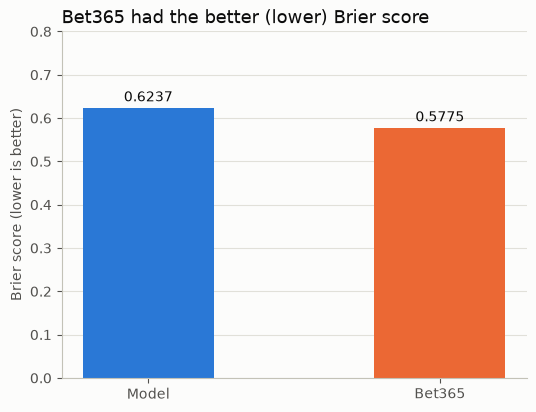

In [28]:
from pathlib import Path

# Create the folder for the saved charts. exist_ok=True means no error if it's already there.
Path("images").mkdir(exist_ok=True)

# Take the two scores from the step 9 results table
brier_names = ["Model", "Bet365"]
brier_scores = [results_table.loc["Model", "Brier score"], results_table.loc["Bookmaker", "Brier score"]]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(brier_names, brier_scores, width=0.45, color=[BLUE, ORANGE])

# With only two bars, each one can carry its value
for name, score in zip(brier_names, brier_scores):
    ax.text(name, score + 0.015, f"{score:.4f}", ha="center", color=TEXT)

ax.set_title("Bet365 had the better (lower) Brier score")
ax.set_ylabel("Brier score (lower is better)")
ax.set_ylim(0, 0.8)           # Start at 0 so that the gap isn't exaggerated
ax.grid(axis="x", visible=False)

# Save before showing, because plt.show() clears the figure
fig.savefig("images/brier_scores.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Bet365's Brier score of 0.5775 was lower than the model's 0.6237, a gap of 0.0462. The bars look fairly close because even good football predictions score well above 0: match results are hard to predict. The simple baseline from step 9 scored 0.6528, so the model sits between the baseline and the bookmaker.

A well-calibrated predictor's probabilities match reality: of all the times it says "40%", the event should happen about 40% of the time. To test this, the next cell takes every probability given (three per match), groups them into bands of 10 percentage points, and compares each band's average prediction with how often those events actually happened. Points on the diagonal line are perfectly calibrated.

Predictor       band  predictions  average_predicted  actually_happened
   Bet365 (0.0, 0.1]           22              0.077              0.091
   Bet365 (0.1, 0.2]          189              0.157              0.148
   Bet365 (0.2, 0.3]          383              0.251              0.251
   Bet365 (0.3, 0.4]          145              0.353              0.372
   Bet365 (0.4, 0.5]          100              0.449              0.470
   Bet365 (0.5, 0.6]           84              0.556              0.488
   Bet365 (0.6, 0.7]           61              0.652              0.705
   Bet365 (0.7, 0.8]           32              0.734              0.656
   Bet365 (0.8, 0.9]           10              0.825              1.000
    Model (0.0, 0.1]           47              0.070              0.170
    Model (0.1, 0.2]          156              0.157              0.205
    Model (0.2, 0.3]          387              0.244              0.258
    Model (0.3, 0.4]          128              0.347            

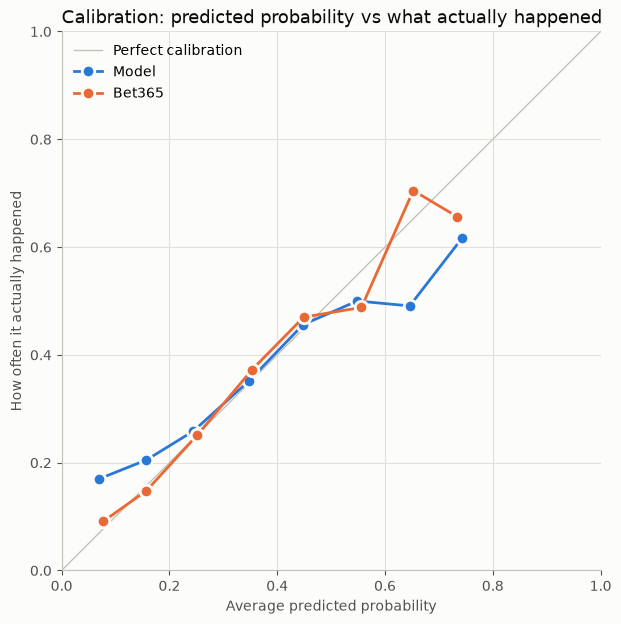

In [29]:
# Build a long table with one row per probability: 342 matches x 3 results x 2 predictors
calibration_rows = []
for name, prefix in [("Model", "model"), ("Bet365", "book")]:
    for result in ["H", "D", "A"]:
        calibration_rows.append(pd.DataFrame({
            "Predictor": name,
            "probability": predictions[f"{prefix}_{result}"],
            "happened": (predictions["FTR"] == result).astype(int),
        }))
calibration_data = pd.concat(calibration_rows, ignore_index=True)

# pd.cut puts each probability into a band: 0-10%, 10-20% and so on
calibration_data["band"] = pd.cut(calibration_data["probability"], bins=np.arange(0, 1.01, 0.1))

# For each band, count the predictions, then compare the average prediction with how often it happened.
# observed=True leaves out any band with no predictions.
calibration_table = calibration_data.groupby(["Predictor", "band"], observed=True).agg(
    predictions=("probability", "size"),
    average_predicted=("probability", "mean"),
    actually_happened=("happened", "mean"),
).reset_index()
print(calibration_table.round(3).to_string(index=False))

# Bands with few predictions are mostly noise, so only plot those with at least 20
MINIMUM_PREDICTIONS = 20
plot_table = calibration_table[calibration_table["predictions"] >= MINIMUM_PREDICTIONS]

fig, ax = plt.subplots(figsize=(7, 7))

# The diagonal shows perfect calibration, where predicted = actual
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, label="Perfect calibration")

for name, colour in [("Model", BLUE), ("Bet365", ORANGE)]:
    band_rows = plot_table[plot_table["Predictor"] == name]
    ax.plot(band_rows["average_predicted"], band_rows["actually_happened"], label=name, color=colour,
            linewidth=2, marker="o", markersize=9, markeredgecolor=BACKGROUND, markeredgewidth=2)

ax.set_title("Calibration: predicted probability vs what actually happened")
ax.set_xlabel("Average predicted probability")
ax.set_ylabel("How often it actually happened")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")        # Make the scales match so that the diagonal is a true 45 degrees
ax.legend(frameon=False, loc="upper left")

fig.savefig("images/calibration.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Between about 20% and 50%, both predictors were well calibrated. The model's problem is at the extremes, where it was overconfident. When it gave 60-70%, the event happened 49.1% of the time, and when it gave 70-80%, the event happened 61.8% of the time. When it gave under 10%, the event still happened 17.0% of the time. Bet365 stayed closer to the diagonal, within about 8 percentage points in every plotted band.

**Notes on this chart:** Bands with fewer than 20 predictions aren't plotted because they're mostly noise, though the table above shows all of them. Those left out are the model's 80-90% (16 predictions) and 90-100% (3) bands, and Bet365's 80-90% band (10). Each match gives three linked probabilities, so the points aren't fully independent, and some bands are small.